# VAE-based with PyTorch
### Example with MNIST datas (possible 1D, 2D or 3D)
## 1. Import des bibliothèques python

In [24]:
%load_ext autoreload
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

# personnal
import libraries
import libraries.data_loader as dl
from libraries.display import display_group_images

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 2. Display training losses 

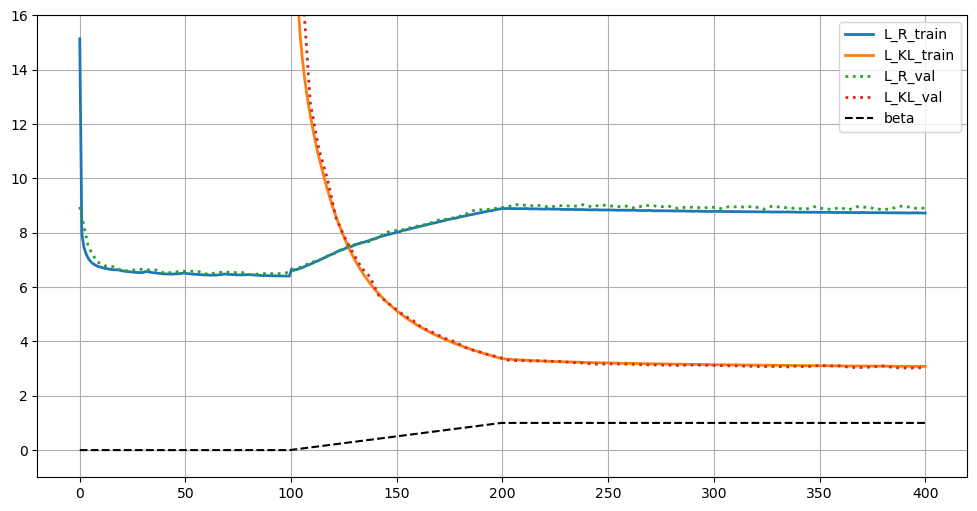

In [78]:
reps = os.listdir(f"results\\VAE")[-1:]
fig = plt.figure(len(reps), figsize = (12, 6))
D = 50
beta = 1.0
ef = 60000
epochs = [400]

for r, rep in enumerate(reps) :
    ep = epochs[r]
    results_rep = f"results\\VAE\\D_{D}-beta_{beta}-eff_{ef}-epoch_{ep}"
    
    AVG_loss = pd.read_csv(results_rep + "\\loss.csv")
    Val_loss = pd.read_csv(results_rep + "\\validation_loss.csv")
    learning_rates = pd.read_csv(results_rep + "\\learning_rate.csv")

    length = np.prod(np.array(AVG_loss).shape)
    length_2 = np.prod(np.array(Val_loss).shape)
    n = epochs[r]
    n_val = epochs[r]//4
    idx = 0

    plt.subplot(1, len(reps), r+1)
    a_range_train = np.linspace(idx, n, n)
    a_range_val = np.linspace(idx, n, n_val)
    a_train = np.array(AVG_loss).reshape(n, length//(n*3), 3).mean(axis = 1)[:, 1:]
    a_val = np.array(Val_loss).reshape(n_val, length_2//(n_val*3), 3).mean(axis = 1)[:, 1:]
    
    plt.plot(a_range_train, a_train[idx:], linewidth = 2)
    plt.plot(a_range_val, a_val[idx:], linewidth = 2, linestyle = "dotted")

    a2 = np.array(learning_rates)[:, -1:].reshape(n, length//(n*3), 1).mean(axis = 1)
    plt.plot(a_range_train, a2[idx:], color = "k", linestyle = "dashed")
    # plt.title(f"(Train;Val): ({ef};{10000}) - Epochs {ep}")
    plt.grid()
    
    plt.ylim((-1, 16))
    plt.legend([s+"_train" for s in str_loss_colnames[1:]] + [s+"_val" for s in str_loss_colnames[1:]] + ["beta"])

plt.savefig(f"results\\IMG\\training_loss.pdf", bbox_inches = "tight")
plt.show()

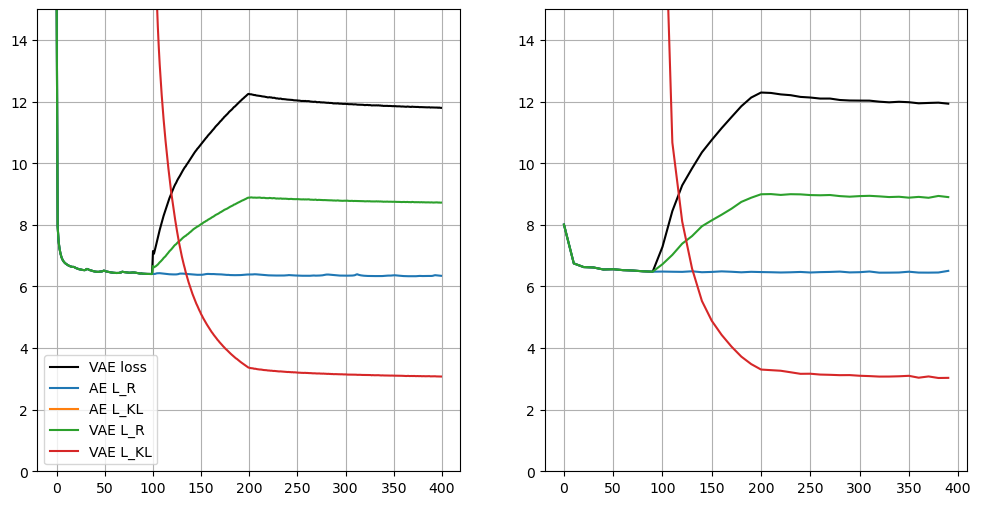

In [80]:
import matplotlib.colors as mcolors

reps = os.listdir(f"results\\VAE")[-2:]
fig = plt.figure(len(reps), figsize = (12, 6))
ef = 60000
ep = 400
D = 50

reps = [f"results\\VAE\\D_{D}-beta_{b}-eff_{ef}-epoch_{ep}" for b in ["0.0", "1.0"]]
AVGS = [pd.read_csv(rep + "\\loss.csv") for rep in reps] 
Vals = [pd.read_csv(rep + "\\validation_loss.csv") for rep in reps] 

AE_losses = np.array(AVGS[0].iloc[:, 1:3]).reshape(400, 300, 2).mean(axis = 1)
VAE_losses = np.array(AVGS[1].iloc[:, 0:3]).reshape(400, 300, 3).mean(axis = 1)

x_val = np.arange(0, 400, 10)
AE_val_losses = np.array(Vals[0].iloc[:, 1:3]).reshape(40, 100, 2).mean(axis = 1)
VAE_val_losses = np.array(Vals[1].iloc[:, 0:3]).reshape(40, 100, 3).mean(axis = 1)

legend = ["VAE loss", "AE L_R", "AE L_KL", "VAE L_R", "VAE L_KL"]
colors = ["k"] + list(mcolors.TABLEAU_COLORS.keys())
plotable = np.array([VAE_losses[:, 0].T] + list(AE_losses.T) + list(VAE_losses[:, 1:].T))
plotable_val = np.array([VAE_val_losses[:, 0].T] + list(AE_val_losses.T) + list(VAE_val_losses[:, 1:].T))


plt.subplot(1, 2, 1)
for v, vals in enumerate(plotable) :
    plt.plot(vals, color = colors[v])
plt.ylim((0, 15))
plt.grid()
plt.legend(legend)
# plt.title("AE losses VS VAE_losses on train dataset")

plt.subplot(1, 2, 2)
for v, vals in enumerate(plotable_val) :
    plt.plot(x_val, vals, color = colors[v])
# plt.title("AE_losses VS VAE_losses on validation dataset")
    
plt.ylim((0, 15))
plt.grid()
plt.savefig(f"results\\IMG\\AE_VAE_loss_comparison.pdf", bbox_inches = "tight")


# 3. Display Latent looks

## 3.1. MNIST

In [169]:
path = r"datas/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

X_TRAIN, Y_TRAIN, X_VAL, Y_VAL = dl.load_datas(path, keys)


X_TRAIN = X_TRAIN.reshape((60000, 1, 28, 28))
X_VAL = X_VAL[:].reshape((10000, 1, 28, 28))


X_TRAIN.shape, X_VAL.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

## 3.2. VAE trained Model

In [172]:
D = 50
ef = len(X_TRAIN)
ep = 400
b = 1.0

rep = f"results\\VAE\\D_{D}-beta_{b}-eff_{ef}-epoch_{ep}"
net = torch.load(rep + r"\model.pt", weights_only=False)
net.train(False)

VAE(
  (vae): VAE_based(
    (Encoder): Encoder(
      (CNN): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU()
        (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (8): ReLU()
        (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (11): ReLU()
      )
      (Linear): Linear(in_features=2048, out_features=100, bias=True)
    )
    (Decoder): Decoder(
      (Linear): Linear(in_features=50, out_feat

In [175]:
%autoreload 2
from libraries.latent import get_MU_LOGVAR, get_Asquare, Z_to_hat_X

In [176]:
batchsize = 10000
MU, LOGVAR = get_MU_LOGVAR(net, X_TRAIN, batchsize)
MU_test, LOGVAR_test = get_MU_LOGVAR(net, X_VAL, batchsize)

In [177]:
MU.shape, LOGVAR.shape, MU_test.shape, LOGVAR_test.shape

((60000, 50), (60000, 50), (10000, 50), (10000, 50))

In [178]:
Asquare_train = get_Asquare(MU, np.exp(LOGVAR))
Asquare_test = get_Asquare(MU_test, np.exp(LOGVAR_test))

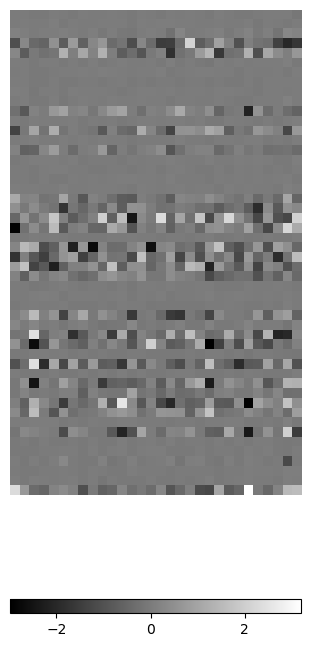

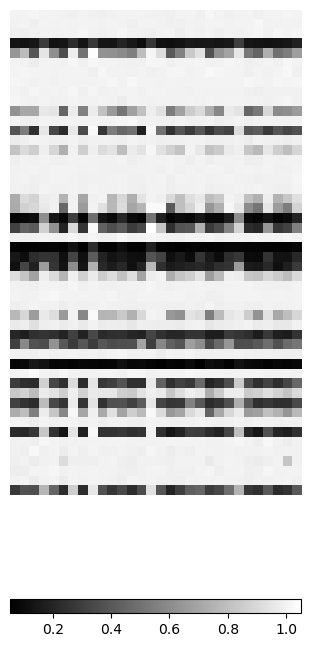

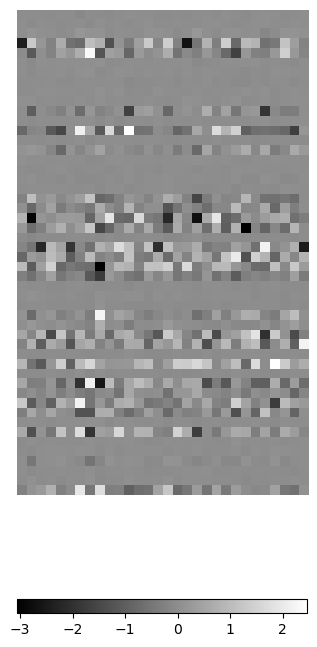

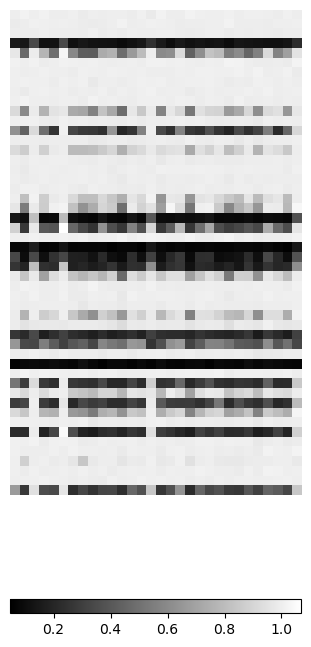

In [179]:
files = ["MU", "SIGMA", "MU_test", "SIGMA_test"]
files_sorted = [file +"_sorted" for file in files]

latents = [MU, np.exp(LOGVAR/2), MU_test, np.exp(LOGVAR_test/2)]

for file, latent in zip(files, latents) :
    plt.figure(figsize = (15, 9))
    plt.imshow(latent[:30].T, cmap = "gray")
    plt.axis("off")
    plt.colorbar(orientation = "horizontal", shrink = 0.25)
    plt.savefig(f"results\\IMG\\{file}.png", bbox_inches = "tight")
    plt.show()

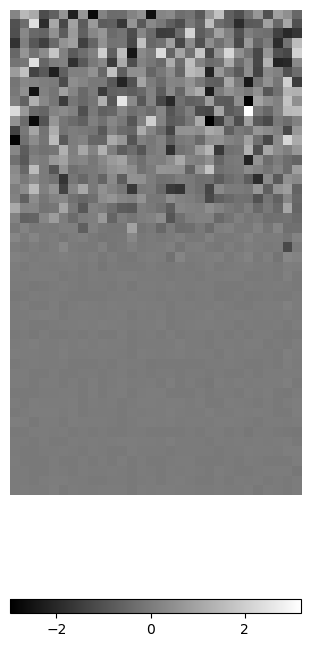

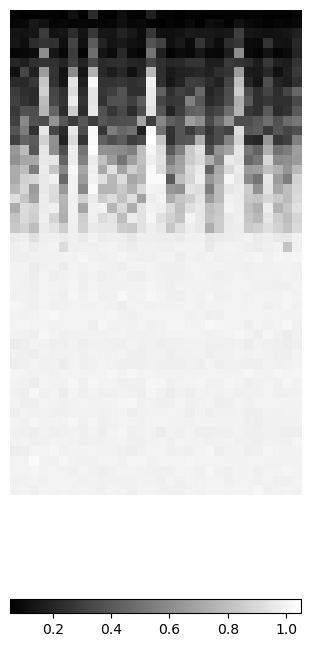

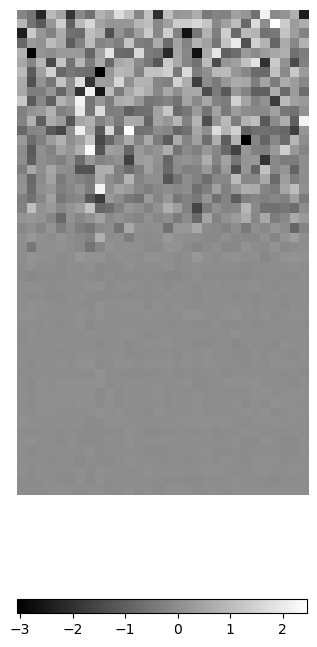

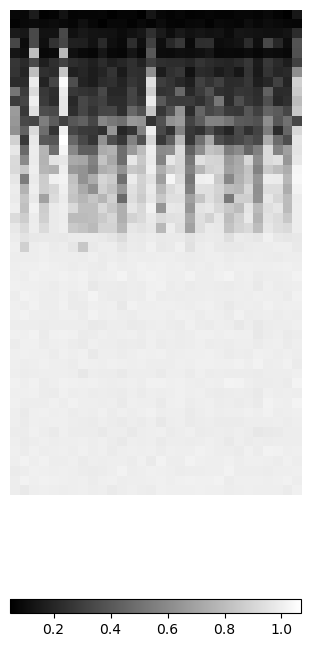

In [180]:
files_sorted = [file +"_sorted" for file in files]
latents_sorted = [MU[:, Asquare_train["index"]], np.exp(LOGVAR/2)[:, Asquare_train["index"]], 
                  MU_test[:, Asquare_test["index"]], np.exp(LOGVAR_test/2)[:, Asquare_test["index"]]]

for file, latent in zip(files_sorted, latents_sorted) :
    plt.figure(figsize = (15, 9))
    plt.imshow(latent[:30].T, cmap = "gray")
    plt.axis("off")
    plt.colorbar(orientation = "horizontal", shrink = 0.25)
    plt.savefig(f"results\\IMG\\{file}.png", bbox_inches = "tight")
    plt.show()

In [181]:
Asquare_train["Tab"] = [f"{val:3.0f}" for val in Asquare_train[0]]
Asquare_test["Tab"] = [f"{val:3.0f}" for val in Asquare_test[0]]

In [182]:
Asquare_train[["index", "Tab"]].sort_values(by = "index", ascending = True).to_csv(r"results\Asquare\train.csv", sep = ";", index = False)
Asquare_test[["index", "Tab"]].sort_values(by = "index", ascending = True).to_csv(r"results\Asquare\test.csv", sep = ";", index = False)

Asquare_train[["index", "Tab"]].to_csv(r"results\Asquare\train_sorted.csv", sep = ";", index = False)
Asquare_test[["index", "Tab"]].to_csv(r"results\Asquare\test_sorted.csv", sep = ";", index = False)

In [183]:
Asquare_train = Asquare_train[["index", 0]]
Asquare_test = Asquare_test[["index", 0]]

Asquare_train.merge(Asquare_test, on="index")


,index,0_x,0_y
0,24,99.403114,99.388176
1,36,99.326363,99.309937
2,3,97.650604,97.536270
3,25,96.476982,96.580505
4,21,95.708138,95.591743
5,33,95.166855,95.223221
6,26,91.147987,90.977409
7,43,86.769997,86.198059
8,38,83.205353,83.717285
9,40,81.724342,81.582611


In [184]:
print(list(Asquare_train["index"]))

[24, 36, 3, 25, 21, 33, 26, 43, 38, 40, 49, 34, 12, 22, 4, 10, 41, 20, 31, 27, 19, 14, 39, 32, 46, 2, 48, 42, 28, 23, 9, 29, 6, 44, 13, 18, 30, 7, 5, 45, 11, 15, 8, 35, 17, 47, 37, 0, 16, 1]


In [185]:
print(list(Asquare_test["index"]))

[24, 36, 3, 25, 21, 33, 26, 43, 38, 40, 49, 34, 12, 22, 4, 10, 41, 20, 31, 27, 19, 14, 39, 32, 46, 2, 48, 23, 42, 28, 29, 9, 13, 44, 18, 7, 6, 30, 5, 11, 45, 8, 15, 35, 17, 47, 0, 1, 37, 16]


In [302]:
MU_test.shape

(10000, 50)

In [303]:
V_act_mix = Asquare_test[Asquare_test[0]>10]["index"]
V_act_mix

0     24
1     36
2      3
3     25
4     21
5     33
6     26
7     43
8     38
9     40
10    49
11    34
12    12
13    22
14     4
15    10
16    41
17    20
18    31
19    27
20    19
21    14
22    39
Name: index, dtype: int64

In [315]:
filename = r"datas\latent_test.csv"
latent_test = pd.DataFrame(MU_test[:, V_act_mix], columns = V_act_mix)
# latent_test = pd.DataFrame(MU_test, columns = range(50))

latent_test.to_csv(filename, index = False)

In [318]:
filename = r"datas\latent_train.csv"
latent_train = pd.DataFrame(MU[:, V_act_mix], columns = V_act_mix)
latent_train.to_csv(filename, index = False)

In [317]:
MU.shape

(60000, 50)

# 4. VAE sensitivity to the replacement of $V_{pas}$ by 0 or of gaussian noise

In [186]:
V_pas = Asquare_train[Asquare_train[0] <= 10]["index"]

## 4.1. On training datas

In [187]:
MU.shape

(60000, 50)

In [243]:
hat_X = Z_to_hat_X(net, MU, 10000)

In [244]:
MU_zeros = MU.copy()
MU_zeros[:, V_pas] = 0.0
hat_X_zeros = Z_to_hat_X(net, MU_zeros, 10000)

In [247]:
((X_train -hat_X)**2).mean(), ((X_train -hat_X_zeros)**2).mean(), ((hat_X -hat_X_zeros)**2).mean()

(0.0054599256, 0.005486531, 1.9649228e-06)

In [191]:
MU_gaus_noise = MU.copy()

np.random.seed(42)
MU_gaus_noise[:, V_pas] = np.random.normal(size = (MU.shape[0], len(V_pas)))
hat_X_gaus_noise = Z_to_hat_X(net, MU_gaus_noise, 10000)

In [192]:
X_train = X_TRAIN.copy().astype(np.float32) /255.

In [193]:
MSE_hat_X =  ((X_train-hat_X)**2).mean()
MSE_hat_X_zeros =  ((X_train-hat_X_zeros)**2).mean()
MSE_hat_X_gaus_nois =  ((X_train-hat_X_gaus_noise)**2).mean()

MSE_hat_X, MSE_hat_X_zeros, MSE_hat_X_gaus_nois

(0.0054599256, 0.005486531, 0.005536614)

In [194]:
MAE_zeros = np.abs(hat_X -hat_X_zeros)
MAE_gaus_noise = np.abs(hat_X -hat_X_gaus_noise)

(MAE_zeros**2).mean(), (MAE_gaus_noise**2).mean()

(1.9649228e-06, 5.4890228e-05)

## 4.2. On testing datas

In [ ]:
hat_X_test = Z_to_hat_X(net, MU_test, 10000)

In [241]:
MU_test_zeros = MU_test.copy()
MU_test_zeros[:, V_pas] = 0.0
hat_X_test_zeros = Z_to_hat_X(net, MU_test_zeros, 10000)

((X_test -hat_X_test)**2).mean(), ((X_test -hat_X_test_zeros)**2).mean(), ((hat_X_test -hat_X_test_zeros)**2).mean()

(0.005965598, 0.0059901145, 1.35509e-06)

In [197]:
MU_test_gaussian = MU_test.copy()

np.random.seed(42)
MU_test_gaussian[:, V_pas] = np.random.normal(size = (MU_test.shape[0], len(V_pas)))
hat_X_test_gaussian = Z_to_hat_X(net, MU_test_gaussian, 10000)

In [198]:
X_test = X_VAL.copy().astype(np.float32) /255.
MSE_hat_X_test =  ((X_test-hat_X_test)**2).mean()
MSE_hat_X_test_zeros =  ((X_test-hat_X_test_zeros)**2).mean()
MSE_hat_X_test_gaussian =  ((X_test-hat_X_test_gaussian)**2).mean()

MSE_hat_X_test, MSE_hat_X_test_zeros, MSE_hat_X_test_gaussian

(0.005965598, 0.0059901145, 0.006037728)

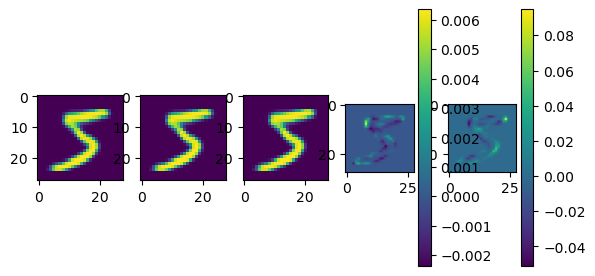

In [199]:
fig, axes = plt.subplots(1, 5)
axes[0].imshow(hat_X[0, 0])
axes[1].imshow(hat_X_zeros[0, 0])
axes[2].imshow(hat_X_gaus_noise[0, 0])
im3 = axes[3].imshow(hat_X[0, 0]-hat_X_zeros[0, 0])
im4 = axes[4].imshow(hat_X[0, 0]-hat_X_gaus_noise[0, 0])

plt.colorbar(im3)
plt.colorbar(im4)

### 4.2.2. Gaussian sensitivity via Monte Carlo 

In [ ]:
MC = 5000

MU_test_gaussian = MU_test.copy()
x_x_gaus = []
hat_x_x_gaus = []

np.random.seed(42)
for mc in range(MC) : 
    print(mc, "->", end = " ")
    MU_test_gaussian[:, V_pas] = np.random.normal(size = (MU_test.shape[0], len(V_pas)))
    hat_X_test_gaussian = Z_to_hat_X(net, MU_test_gaussian, 10000)

    all_MAE = np.abs(X_test-hat_X_test_gaussian)
    all_hat_MAE = np.abs(hat_X_test -hat_X_test_gaussian)
    x_x_gaus.append((all_MAE**2).mean())
    hat_x_x_gaus.append((all_hat_MAE**2).mean())
    
    # quantiles.append([np.quantile(all_MAE, q) for q in np.arange(0, 1.1, 0.1)])
    

In [ ]:
filename = r"results\Asquare\sensitivity\test.npz"
np.savez(filename, x_x_gaus = np.array(x_x_gaus), hat_x_x_gaus = np.array(hat_x_x_gaus), allow_pickle=False)

In [291]:
with np.load(filename) as f :
    x_x_gaus = f["x_x_gaus"]
    hat_x_x_gaus = f["hat_x_x_gaus"]

x_x_gaus.shape, hat_x_x_gaus.shape

((5000,), (5000,))

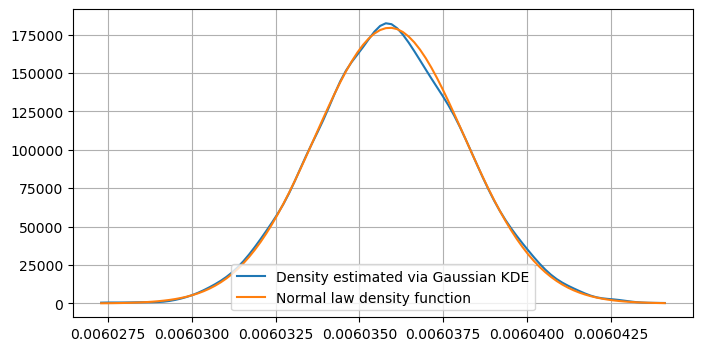

In [295]:
import scipy.stats as stats

plt.figure(figsize = (8, 4))
kde_MSE = stats.gaussian_kde(x_x_gaus)
mi = [min(x_x_gaus), max(x_x_gaus)]
xs = np.linspace(mi[0], mi[1], 100)
ys = kde_MSE(xs)


plt.plot(xs, ys)
ys = stats.norm.pdf(xs, loc = x_x_gaus.mean(), scale = x_x_gaus.std())
plt.plot(xs, ys)
plt.grid()
plt.legend(["Density estimated via Gaussian KDE", "Normal law density function"])

In [300]:
std, mu = x_x_gaus.std(), x_x_gaus.mean()
fract = std/np.sqrt(5000) *2.576
CV = std/mu
mu, std, fract, CV

(0.006035905, 2.222792e-06, 8.097663009791715e-08, 0.00036826162)

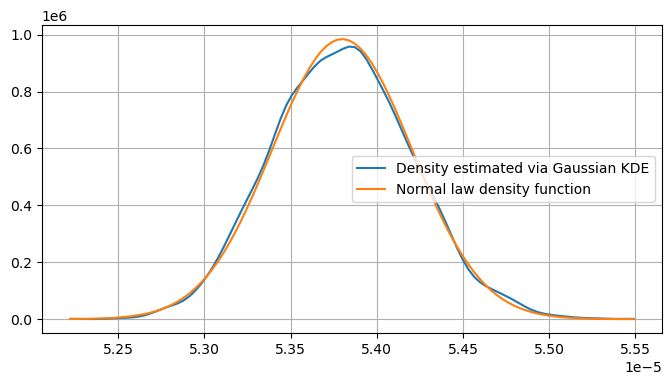

In [296]:
import scipy.stats as stats

plt.figure(figsize = (8, 4))
kde_MSE = stats.gaussian_kde(hat_x_x_gaus)
mi = [min(hat_x_x_gaus), max(hat_x_x_gaus)]
xs = np.linspace(mi[0], mi[1], 100)
ys = kde_MSE(xs)


plt.plot(xs, ys)
ys = stats.norm.pdf(xs, loc = hat_x_x_gaus.mean(), scale = hat_x_x_gaus.std())
plt.plot(xs, ys)
plt.grid()
plt.legend(["Density estimated via Gaussian KDE", "Normal law density function"])

In [301]:
std, mu = hat_x_x_gaus.std(), hat_x_x_gaus.mean()
fract = std/np.sqrt(5000) *2.576
CV = std/mu
mu, std, fract, CV

(5.3798885e-05, 4.051907e-07, 1.4761154113154916e-08, 0.0075315814)

(2.222792e-06, 0.006035905)

## 4.2. Replacement by gaussian noise on train en test datas